# VGGMM experiments — shape2 initialization
모델은 vggmm_merge_refit.py, 공통 평가·표·그림은 vggmm_experiments.py에서 불러옵니다.
두 .py와 이 노트북을 같은 폴더에 두고, VS Code에서 그 폴더를 열어 실행하세요.

모든 GGMM 최초 성분과 병합 성분은 b=2에서 출발합니다. 이후 b는 자유롭게 추정합니다.
생성에 사용하는 참 GGD의 형상 (1.5, 4, 8 등)은 바꾸지 않습니다.
기존 moment 출력은 옮기지 않았습니다. 아래 출력은 새 설정으로 다시 계산됩니다.
전체 실행은 여러 번의 실제 적합을 수행합니다. 한 실험만 필요하면 준비 셀 뒤 해당 셀을 실행하세요.

검증 출력은 준비 셀과 N=5,000의 단일 cap=10 실행입니다. 나머지 원래 크기의 실험은 미실행 상태입니다.


In [1]:
from pathlib import Path
import importlib
import numpy as np
import pandas as pd
import vggmm_merge_refit as vg
import vggmm_experiments as ex

importlib.reload(vg)
importlib.reload(ex)

N = 5000
SEED = 20260912
SEEDS = (20260912, 20260913, 20260914)
CAPS = (10, 11, 12, 13, 14, 15)
BASE_CONFIG = vg.VGGMMConfig(initial_shape_mode="shape2", enable_merge=True)
OUTPUT_ROOT = Path("results")
FIGURE_FORMATS = ("png", "svg", "pdf")
ex.check_mathematics()
print("Model:", Path(vg.__file__).name, "| initialization:", BASE_CONFIG.initial_shape_mode)

Math checks passed: normal moment, Gamma profile/ELBO, sticks.
Model: vggmm_merge_refit.py | initialization: shape2


## 표본 준비
기존 세 GGD 생성식과 표본 추출 순서를 유지합니다. 추정기에 주는 입력은 X뿐입니다.


In [2]:
truth3 = ex.ggd_reference_3()
X = ex.sample_mixture(truth3, N, SEED)
X.setflags(write=False)
print(f"N={len(X):,}; seed={SEED}; true K={truth3.k}")

N=5,000; seed=20260912; true K=3


## 1. 최대 성분 수 10 한 번의 실험
두 초기화와 merge 탐색을 포함하는 fit(X) 한 번입니다. 시간·오차·수렴·밀도·성분 그래프를 표시합니다.
Fit_s(merge)는 baseline을 포함합니다. baseline과 merge 시간을 다시 합산하지 않습니다.



max_K=10: baseline + merge (shape2)
    merge (8, 9): K 10->9, ELBO/n +0.00384146
    merge (7, 8): K 9->8, ELBO/n +0.00360525
    merge (6, 7): K 8->7, ELBO/n +0.00381048
    merge (5, 6): K 7->6, ELBO/n +0.00392841
    merge (0, 1): K 6->5, ELBO/n +0.000559903
    merge (3, 4): K 5->4, ELBO/n +0.000513291
    merge (2, 3): K 4->3, ELBO/n +0.000517954
  VGGMM-base: Active_K=10, ELBO/n=-2.4724746, IAE=0.0593097, merges=0
  VGGMM-merge: Active_K=3, ELBO/n=-2.4556025, IAE=0.0292803, merges=7
     Method  Max_K  Active_K  Excluded_mass        IAE          ISE  Converged  Inner_nonconverged  Accepted_merges     Fit_s  Evaluation_s  Quadrature_OK
 VGGMM-base     10        10              0 0.05930967 0.0004962037       True                   0                0  229.9268      0.188242           True
VGGMM-merge     10         3   0.0005995853 0.02928033 9.318173e-05       True                   0                7  288.3944      0.076045           True
        VGM     10         5    0.00127

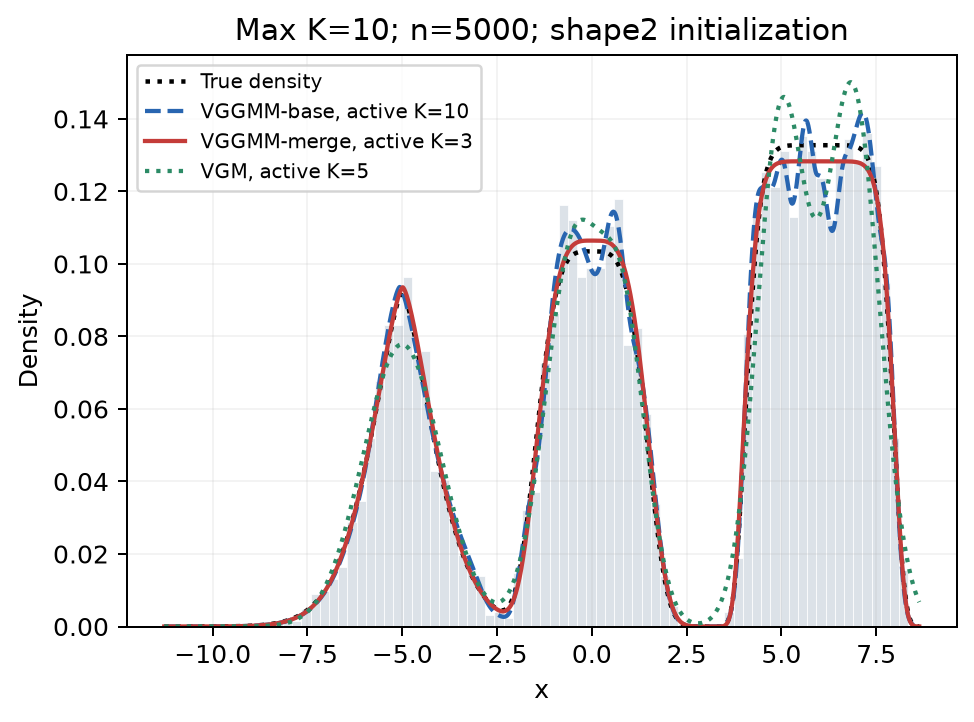

C:\Users\user\.codex\.chatgpt-projects\g-p-69c368eb253081918293f11edcae45d2\output\vggmm_shape2\vggmm_experiments.py:950: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  if show: plt.show()


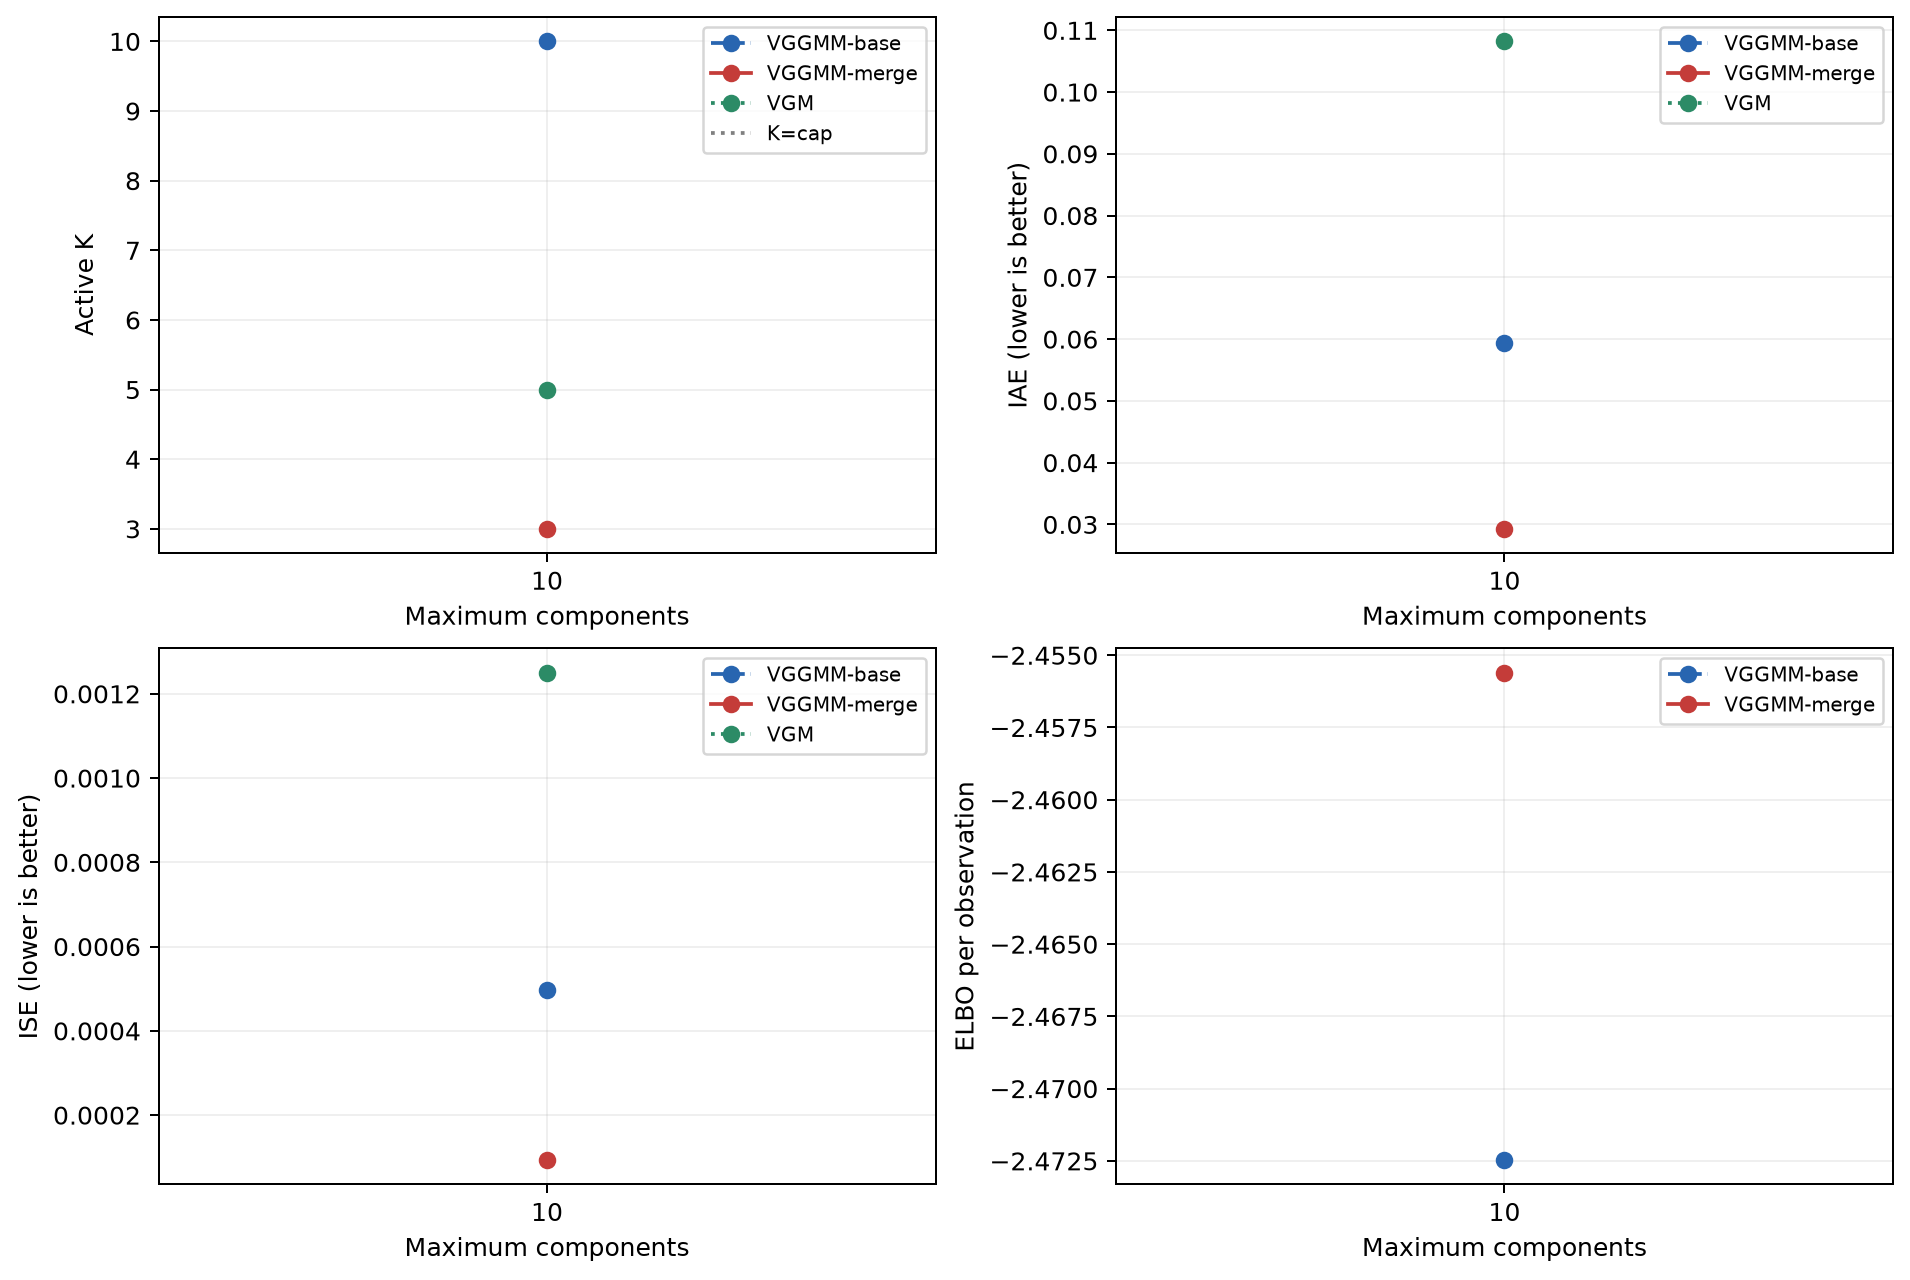

C:\Users\user\.codex\.chatgpt-projects\g-p-69c368eb253081918293f11edcae45d2\output\vggmm_shape2\vggmm_experiments.py:964: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  if show: plt.show()


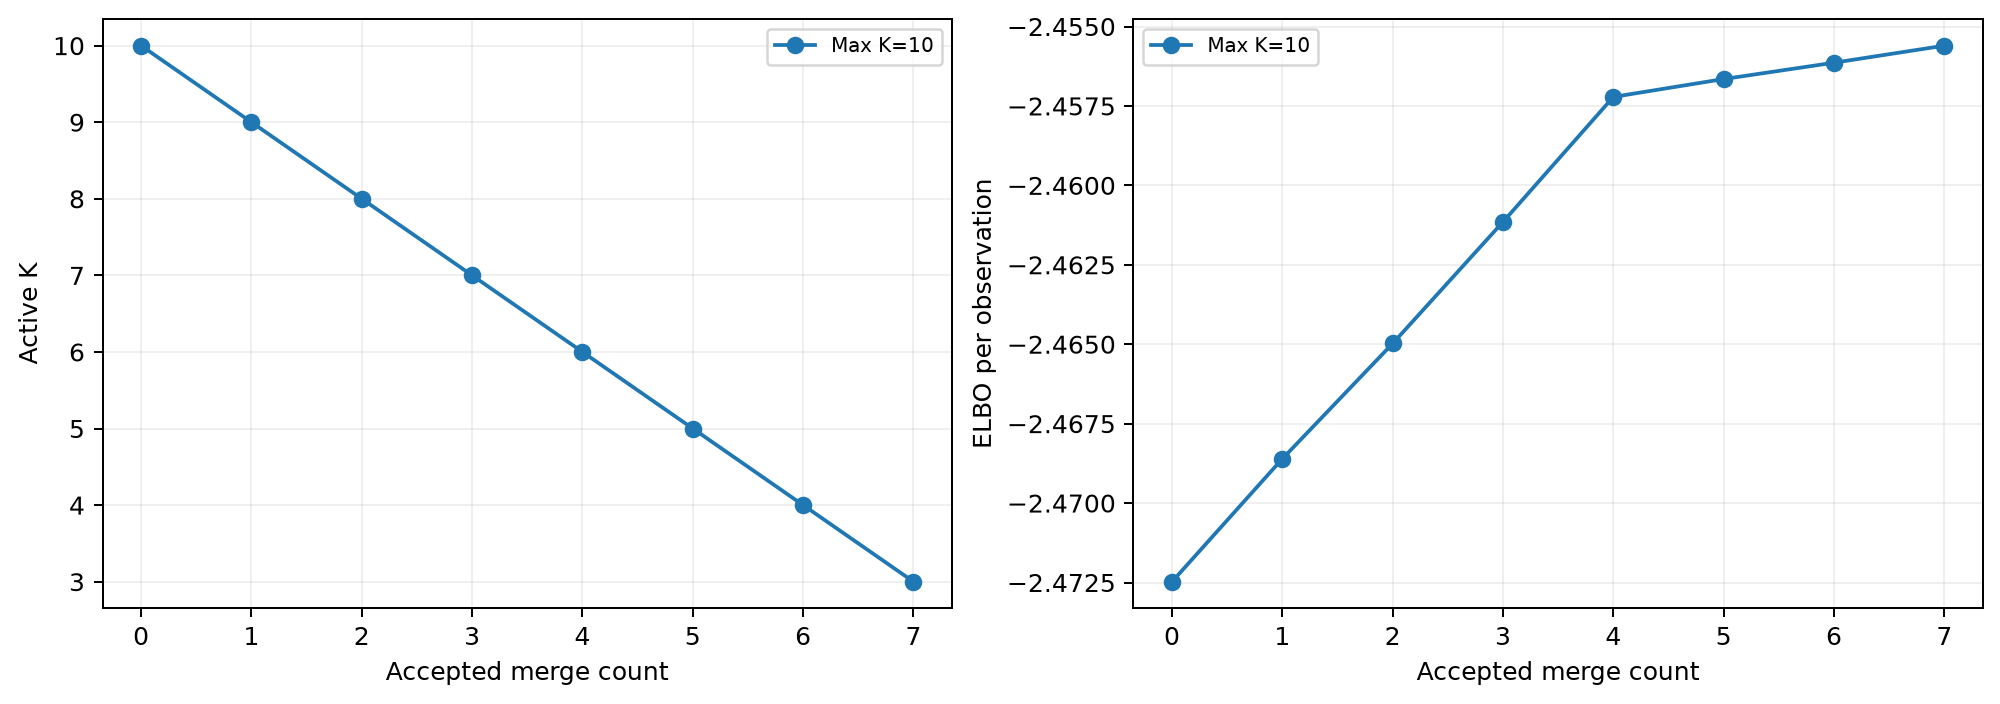

C:\Users\user\.codex\.chatgpt-projects\g-p-69c368eb253081918293f11edcae45d2\output\vggmm_shape2\vggmm_experiments.py:975: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  if show: plt.show()


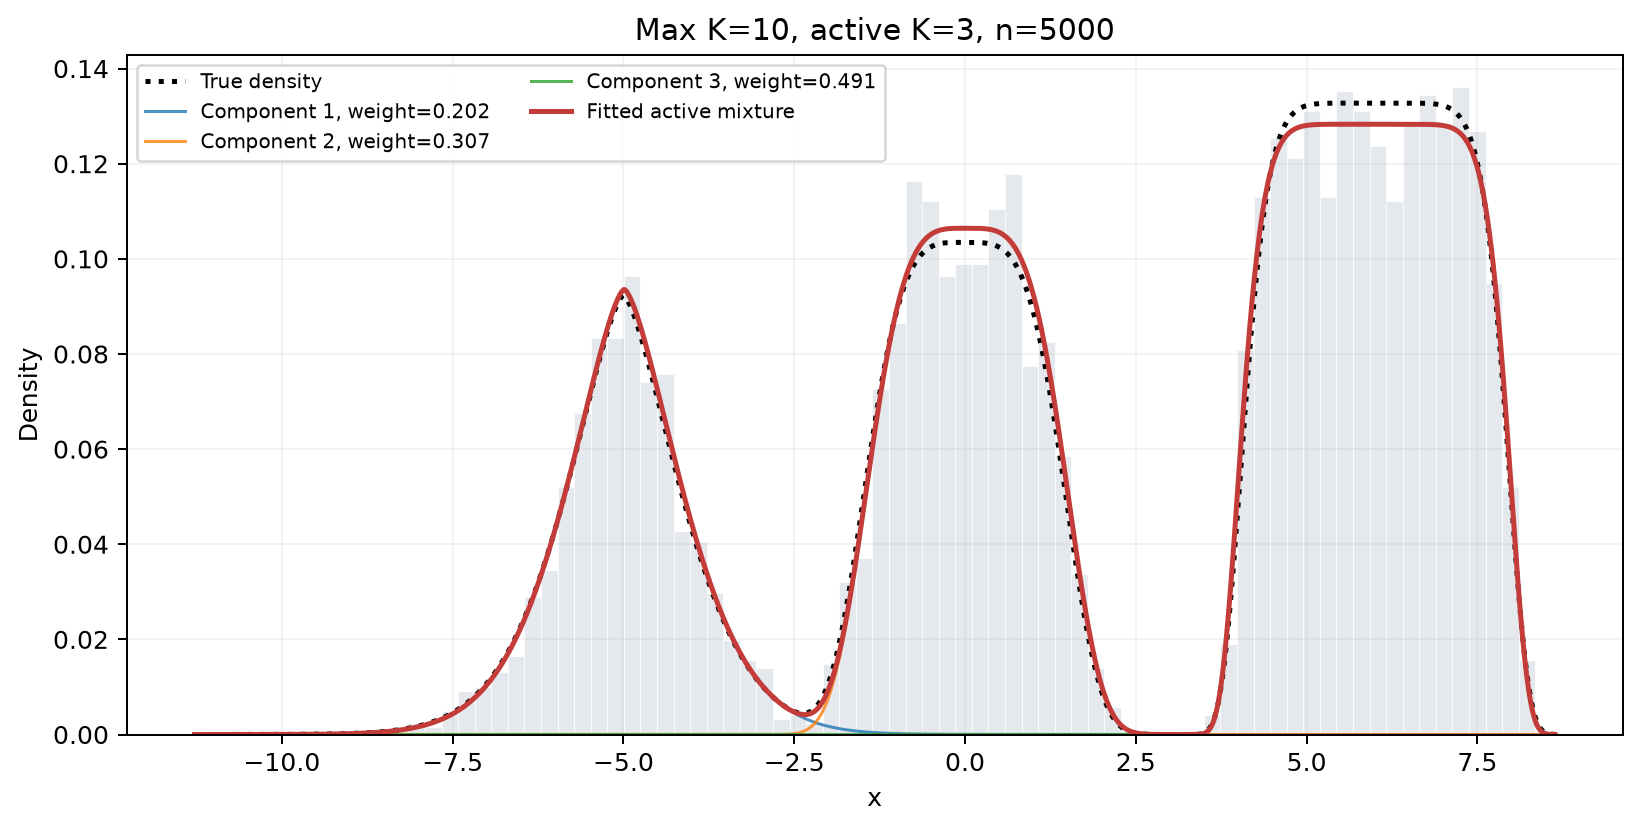

C:\Users\user\.codex\.chatgpt-projects\g-p-69c368eb253081918293f11edcae45d2\output\vggmm_shape2\vggmm_experiments.py:990: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  if show: plt.show()


In [3]:
single_cap = ex.run_cap_experiment(
    X, truth3, caps=(10,), config=BASE_CONFIG,
    name="single_cap_10", output_root=OUTPUT_ROOT, include_vgm=True)
model10 = single_cap["models"][10]
ex.show_cap_results(single_cap)
ex.plot_cap_results(single_cap, formats=FIGURE_FORMATS, components=True)

## 2. 기존 최대 성분 수 10~15 비교
각 상한에서 독립적으로 새 적합을 합니다. 단일 실험과 별도로 소요 시간을 측정합니다.
첫 셀의 CAPS를 (10,)로 지정하면 이 실험도 10 하나만 실행할 수 있습니다.


In [ ]:
cap_sweep = ex.run_cap_experiment(
    X, truth3, caps=CAPS, config=BASE_CONFIG,
    name="cap_sweep", output_root=OUTPUT_ROOT, include_vgm=True)
ex.show_cap_results(cap_sweep)
ex.plot_cap_results(cap_sweep, formats=FIGURE_FORMATS)

## 3. 참 성분 수 5에서 최대 성분 수 3과 10
기존 생성식·표본 수·seed를 유지하며 VGM 없이 병합 전후를 비교합니다.


In [ ]:
truth5 = ex.ggd_reference_5()
X5 = ex.sample_mixture(truth5, N, SEED)
capacity = ex.run_cap_experiment(
    X5, truth5, caps=(3, 10), config=BASE_CONFIG,
    name="capacity_control", output_root=OUTPUT_ROOT, include_vgm=False)
ex.show_cap_results(capacity)
ex.plot_cap_results(capacity, formats=FIGURE_FORMATS)

## 4. 실제 자료 — Abalone Whole_weight
원자료를 먼저 80/20으로 나누고 학습 표본만 fit에 전달합니다. 참 밀도와 참 K는 알려져 있지 않습니다.
data/abalone.data가 없을 때만 공식 UCI 원자료를 내려받습니다. 이 배포 폴더에는 검증에 쓴 원자료 사본이 포함됩니다.


In [ ]:
abalone_x, abalone_metadata = ex.load_abalone()
real_study = ex.run_study(
    "abalone_whole_weight",
    lambda seed: ex.real_sample(abalone_x, abalone_metadata, seed),
    config=BASE_CONFIG, seeds=SEEDS, output_root=OUTPUT_ROOT,
    vgm_n_init=2, formats=FIGURE_FORMATS)

## 5. 순수 Gaussian 세 성분
scale은 정규분포의 표준편차입니다. GGD 척도 a와 구분합니다.
학습 표본과 별도의 독립 테스트 표본은 각각 N개이며 기존 seed와 seed+1000을 사용합니다.


In [ ]:
gaussian_truth = ex.gaussian_reference()
gaussian_study = ex.run_study(
    "gaussian_mixture",
    lambda seed: ex.synthetic_sample(gaussian_truth, seed, n_train=N, n_test=N),
    config=BASE_CONFIG, seeds=SEEDS, output_root=OUTPUT_ROOT,
    vgm_n_init=2, formats=FIGURE_FORMATS)

## 6. 서로 다른 분포족의 혼합
Gaussian + Laplace + Student-t + skew-normal의 기존 생성식입니다.
K=4를 강제하지 않고 full density, 테스트 평균 로그밀도와 IAE·ISE를 평가합니다.


In [ ]:
heterogeneous_truth = ex.heterogeneous_reference()
heterogeneous_study = ex.run_study(
    "heterogeneous_mixture",
    lambda seed: ex.synthetic_sample(heterogeneous_truth, seed, n_train=N, n_test=N),
    config=BASE_CONFIG, seeds=SEEDS, output_root=OUTPUT_ROOT,
    vgm_n_init=2, formats=FIGURE_FORMATS)

## 7. 세 연구의 비교 요약
4~6번 실험을 실행한 뒤 사용합니다. Δ는 VGGMM-merge − 비교방법입니다.
ΔIAE·ΔISE·ΔFit_s는 작을수록, ΔTest_LL_per_obs는 클수록 좋습니다.


In [ ]:
studies = (real_study, gaussian_study, heterogeneous_study)
battery_metrics = pd.concat([s["table"] for s in studies], ignore_index=True)
battery_summary = pd.concat([
    s["paired_summary"].assign(Study=s["metadata"]["study_id"]) for s in studies
], ignore_index=True)
ex.show_table(battery_summary)

## 8. 기존 VGM 전용 상한 대조
참 K=5, 상한 3/10을 GGD 원분포와 평균·분산을 맞춘 Gaussian 대조에서 비교합니다.
공통 IAE·ISE 적분기를 사용하므로 수치 오차 진단과 꼬리 상계도 같은 정의입니다.


In [ ]:
vgm_capacity = ex.run_vgm_cap_experiment(
    n=N, seed=SEED, caps=(3, 10), gaussian_control=True,
    config=BASE_CONFIG, output_root=OUTPUT_ROOT, formats=FIGURE_FORMATS)

## 다른 셀에서 결과 재사용
IAE·ISE를 다시 계산하려면 ex.density_errors(truth3, model10.density_)를 호출하면 됩니다.
이 호출은 재적합하지 않습니다. 전체 슬롯 밀도는 model10.full_density_입니다.

모든 결과는 실험 이름별 results 폴더에 저장됩니다.
적합 수렴, 병합 탐색 종료, 참 K 복원, 밀도 정확도는 별개의 진단입니다.
shape2는 초기 형상만 2로 정하며 b=2 고정 Gaussian 모형으로 바꾸지 않습니다.
